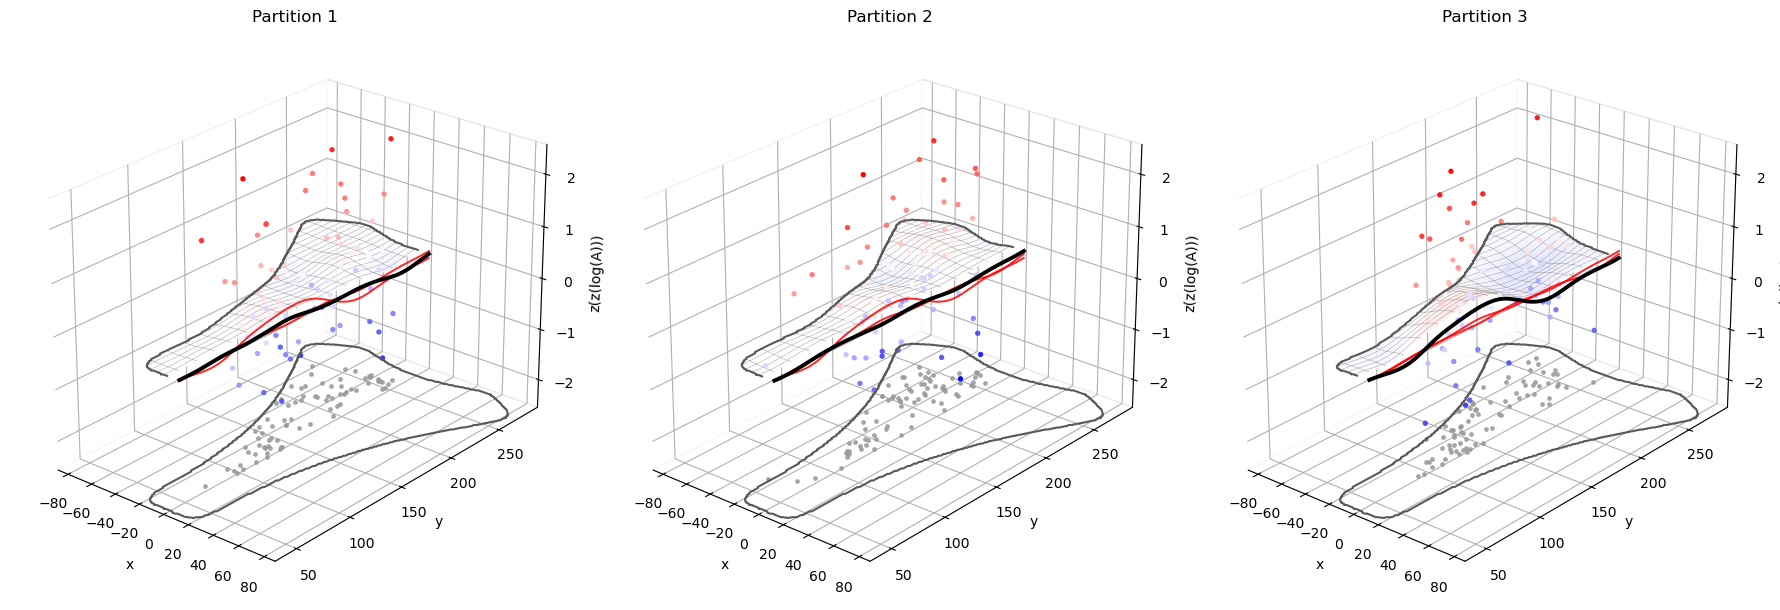

In [1]:
import pickle
import numpy as np
import matplotlib.pyplot as plt

pickle_filename = "../output/adjusted_lambda_splines.pkl"

with open(pickle_filename, "rb") as f:
    data = pickle.load(f)

F_name = data["F_name"]

view_elev = data["view_elev"]
view_azim = data["view_azim"]

active_slice_line_width = data["active_slice_line_width"]
inactive_slice_line_width = data["inactive_slice_line_width"]
inactive_slice_alpha = data["inactive_slice_alpha"]

spline_grid_stride = data["spline_grid_stride"]
spline_grid_linewidth = data["spline_grid_linewidth"]
spline_grid_alpha = data["spline_grid_alpha"]

floor_point_size = data["floor_point_size"]
floor_point_alpha = data["floor_point_alpha"]

x_abs_max = data["x_abs_max"]
x_span = data["x_span"]
y_span = data["y_span"]
z_visual_scale = data["z_visual_scale"]

plot_z_min = data["plot_z_min"]
plot_z_max = data["plot_z_max"]

edge_knots = data["edge_knots"]

border_x = data["border_x"]
border_y = data["border_y"]

border_x_left = data["border_x_left"]
border_y_left = data["border_y_left"]

y_grid_left = data["y_grid_left"]

xx_left = data["xx_left"]
yy_left = data["yy_left"]

inside_grid = data["inside_grid"]
inside_slice = data["inside_slice"]

x0_plot = data["x0_plot"]

plot_data = data["plot_data"]

def plot_masked_wireframe(
    ax,
    X,
    Y,
    Z,
    mask,
    rstride,
    cstride,
    color,
    linewidth,
    alpha,
    zorder,
):
    def draw_segments(
        x_line,
        y_line,
        z_line,
        m_line,
    ):
        start = None

        for i, ok in enumerate(m_line):
            if ok and start is None:
                start = i

            if (
                not ok
                or i == len(m_line) - 1
            ) and start is not None:
                end = (
                    i
                    if not ok
                    else i + 1
                )

                if end - start >= 2:
                    ax.plot(
                        x_line[start:end],
                        y_line[start:end],
                        z_line[start:end],
                        color=color,
                        linewidth=linewidth,
                        alpha=alpha,
                        zorder=zorder,
                    )

                start = None

    for i in range(
        0,
        X.shape[0],
        rstride,
    ):
        draw_segments(
            X[i, :],
            Y[i, :],
            Z[i, :],
            mask[i, :],
        )

    for j in range(
        0,
        X.shape[1],
        cstride,
    ):
        draw_segments(
            X[:, j],
            Y[:, j],
            Z[:, j],
            mask[:, j],
        )

all_slices = [
    np.ma.masked_where(
        ~inside_slice,
        item["slice_raw"],
    )
    for item in plot_data
]

floor_outline_z = np.full_like(
    border_x,
    plot_z_min,
    dtype=float,
)

fig = plt.figure(
    figsize=(18, 6)
)

axes = [
    fig.add_subplot(
        1,
        3,
        i + 1,
        projection="3d",
        computed_zorder=False,
    )
    for i in range(3)
]

for active_idx, (ax, item) in enumerate(
    zip(
        axes,
        plot_data,
    )
):
    grid = np.ma.masked_where(
        ~inside_grid,
        item["grid_raw"],
    )

    ax.xaxis.pane.set_facecolor(
        (1, 1, 1, 1)
    )

    ax.yaxis.pane.set_facecolor(
        (1, 1, 1, 1)
    )

    ax.zaxis.pane.set_facecolor(
        (1, 1, 1, 1)
    )

    ax.xaxis.pane.set_alpha(1.0)
    ax.yaxis.pane.set_alpha(1.0)
    ax.zaxis.pane.set_alpha(1.0)

    ax.plot_surface(
        xx_left,
        yy_left,
        grid,
        cmap="bwr",
        vmin=plot_z_min,
        vmax=plot_z_max,
        linewidth=0,
        antialiased=True,
        shade=False,
        alpha=1.0,
        zorder=1,
    )

    plot_masked_wireframe(
        ax=ax,
        X=xx_left,
        Y=yy_left,
        Z=item["grid_raw"],
        mask=inside_grid,
        rstride=spline_grid_stride,
        cstride=spline_grid_stride,
        color="0.45",
        linewidth=spline_grid_linewidth,
        alpha=spline_grid_alpha,
        zorder=2,
    )

    ax.scatter(
        item["x"],
        item["y"],
        np.full_like(
            item["x"],
            plot_z_min,
        ),
        s=floor_point_size,
        color="0.6",
        alpha=floor_point_alpha,
        depthshade=False,
        zorder=3,
    )

    ax.scatter(
        item["x"],
        item["y"],
        item["F"],
        s=8,
        c=item["F"],
        cmap="bwr",
        vmin=plot_z_min,
        vmax=plot_z_max,
        depthshade=False,
        zorder=4,
    )

    ax.plot(
        border_x_left,
        border_y_left,
        item["border"],
        color="0.35",
        lw=1.5,
        zorder=5,
    )

    ax.plot(
        border_x,
        border_y,
        floor_outline_z,
        color="0.35",
        lw=1.5,
        zorder=6,
    )

    for slice_idx, slice_z in enumerate(
        all_slices
    ):
        is_active = (
            slice_idx == active_idx
        )

        ax.plot(
            x0_plot,
            y_grid_left,
            slice_z,
            color=(
                "black"
                if is_active
                else "red"
            ),
            lw=(
                active_slice_line_width
                if is_active
                else inactive_slice_line_width
            ),
            alpha=(
                1.0
                if is_active
                else inactive_slice_alpha
            ),
            zorder=(
                201
                if is_active
                else 200
            ),
        )

    ax.set_xlim(
        -x_abs_max,
        x_abs_max,
    )

    ax.set_ylim(
        edge_knots[1][0],
        edge_knots[1][1],
    )

    ax.set_zlim(
        plot_z_min,
        plot_z_max,
    )

    ax.set_box_aspect((
        x_span,
        y_span,
        z_visual_scale,
    ))

    ax.view_init(
        elev=view_elev,
        azim=view_azim,
    )

    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel(
        f"z({F_name})"
    )

    ax.set_title(
        item["title"]
    )

fig.tight_layout()
plt.show()

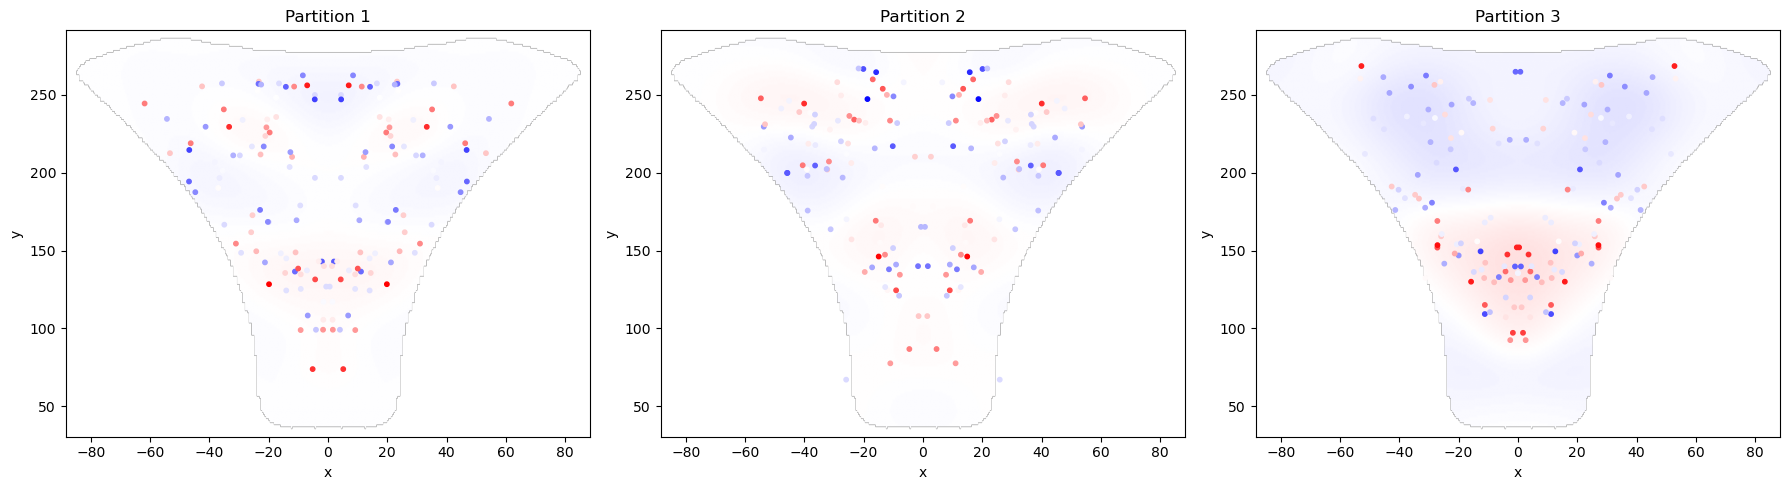

In [2]:
import pickle
import numpy as np
import matplotlib.pyplot as plt

with open("../output/adjusted_lambda_splines.pkl", "rb") as f:
    data = pickle.load(f)

plot_data = data["plot_data"]
x_left = data["x_grid_left"]
y_grid = data["y_grid_left"]
inside_left = data["inside_grid"]

vmin = data["plot_z_min"]
vmax = data["plot_z_max"]

x_full = np.concatenate([
    x_left,
    -x_left[-2::-1],
])

inside_full = np.concatenate([
    inside_left,
    inside_left[:, -2::-1],
], axis=1)

fig, axes = plt.subplots(
    1,
    len(plot_data),
    figsize=(6 * len(plot_data), 5),
    squeeze=False,
)

axes = axes.ravel()

for ax, item in zip(axes, plot_data):
    z_left = item["grid_raw"]

    z_full = np.concatenate([
        z_left,
        z_left[:, -2::-1],
    ], axis=1)

    z_full = np.where(
        inside_full,
        z_full,
        np.nan,
    )

    x_left_pts = item["x"]
    y_left_pts = item["y"]
    f_left_pts = item["F"]

    mirror_mask = x_left_pts < 0

    x_full_pts = np.concatenate([
        x_left_pts,
        -x_left_pts[mirror_mask],
    ])

    y_full_pts = np.concatenate([
        y_left_pts,
        y_left_pts[mirror_mask],
    ])

    f_full_pts = np.concatenate([
        f_left_pts,
        f_left_pts[mirror_mask],
    ])

    im = ax.imshow(
        z_full,
        origin="lower",
        extent=[x_full[0], x_full[-1], y_grid[0], y_grid[-1]],
        cmap="bwr",
        vmin=vmin,
        vmax=vmax,
        aspect="auto",
    )

    ax.scatter(
        x_full_pts,
        y_full_pts,
        c=f_full_pts,
        cmap="bwr",
        vmin=vmin,
        vmax=vmax,
        s=10,
    )

    ax.set_title(item["title"])
    ax.set_xlabel("x")
    ax.set_ylabel("y")

plt.tight_layout()
plt.show()